<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session13_association_rules_and_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۳: قوانین انجمنی و تشخیص ناهنجاری

### اهداف این جلسه

- آشنایی با **تحلیل سبد خرید** و قوانین انجمنی
- معیارهای **Support**، **Confidence** و **Lift**
- الگوریتم‌های **Apriori** و **FP-Growth**
- آشنایی با **تشخیص ناهنجاری (Anomaly Detection)** و کاربردهای آن
- روش‌های آماری ساده: Z-score و IQR
- روش‌های یادگیری ماشین: **Isolation Forest**، **LOF**، **One-Class SVM** و **Elliptic Envelope**
- استفادهٔ درست از این روش‌ها بدون نشت داده

## بخش اول: قوانین انجمنی (Association Rules)

## ۱. تحلیل سبد خرید

فروشگاه‌ها می‌خواهند بدانند **کدام کالاها با هم خریده می‌شوند**؛ برای چیدمان قفسه‌ها، پیشنهاد محصول («مشتریانی که این را خریدند، آن را هم خریدند») و طراحی تخفیف‌های ترکیبی.

یک **قانون انجمنی** به شکل $A \Rightarrow B$ است: «اگر مشتری $A$ را بخرد، احتمالاً $B$ را هم می‌خرد». $A$ را **مقدم (antecedent)** و $B$ را **تالی (consequent)** می‌نامیم.

## ۲. معیارها

$$\text{Support}(A) = \frac{\text{transactions containing } A}{\text{all transactions}} \qquad \text{Confidence}(A \Rightarrow B) = \frac{\text{Support}(A \cup B)}{\text{Support}(A)} \qquad \text{Lift}(A \Rightarrow B) = \frac{\text{Confidence}(A \Rightarrow B)}{\text{Support}(B)}$$

- **Support:** چه سهمی از کل تراکنش‌ها شامل این مجموعه کالاست؟ قانون‌های با Support کم ممکن است تصادفی باشند.
- **Confidence:** از مشتریانی که $A$ را خریده‌اند، چند درصد $B$ را هم خریده‌اند؟ همان احتمال شرطی $P(B \mid A)$.
- **Lift:** خرید $A$ احتمال خرید $B$ را چند برابر می‌کند؟
  - $\text{Lift} > 1$: رابطهٔ مثبت؛ با هم خریده می‌شوند.
  - $\text{Lift} = 1$: مستقل‌اند.
  - $\text{Lift} < 1$: رابطهٔ منفی؛ جایگزین هم‌اند.

**چرا Confidence کافی نیست؟** اگر ۹۰٪ همهٔ مشتریان نان بخرند، قانون «قهوه ⇐ نان» Confidence بالایی دارد، فقط چون نان پرفروش است؛ نه به خاطر رابطهٔ واقعی با قهوه. Lift این اثر را با تقسیم بر محبوبیت $B$ اصلاح می‌کند.

## ۳. داده: تراکنش‌های یک فروشگاه

داده شامل ۷۵۰۱ تراکنش یک فروشگاه در یک هفته است. هر سطر، کالاهای یک خرید است و تعداد کالاها در سطرها متفاوت است.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
raw = pd.read_csv(DATA_URL + "Market_Basket_Optimisation.csv", header=None)
transactions = [row.dropna().str.strip().tolist() for _, row in raw.iterrows()]

print("Number of transactions:", len(transactions))
print("Average basket size:", round(np.mean([len(t) for t in transactions]), 2))
print("Examples:", transactions[:3])

Number of transactions: 7501
Average basket size: 3.91
Examples: [['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil'], ['burgers', 'meatballs', 'eggs'], ['chutney']]


Number of distinct items: 119


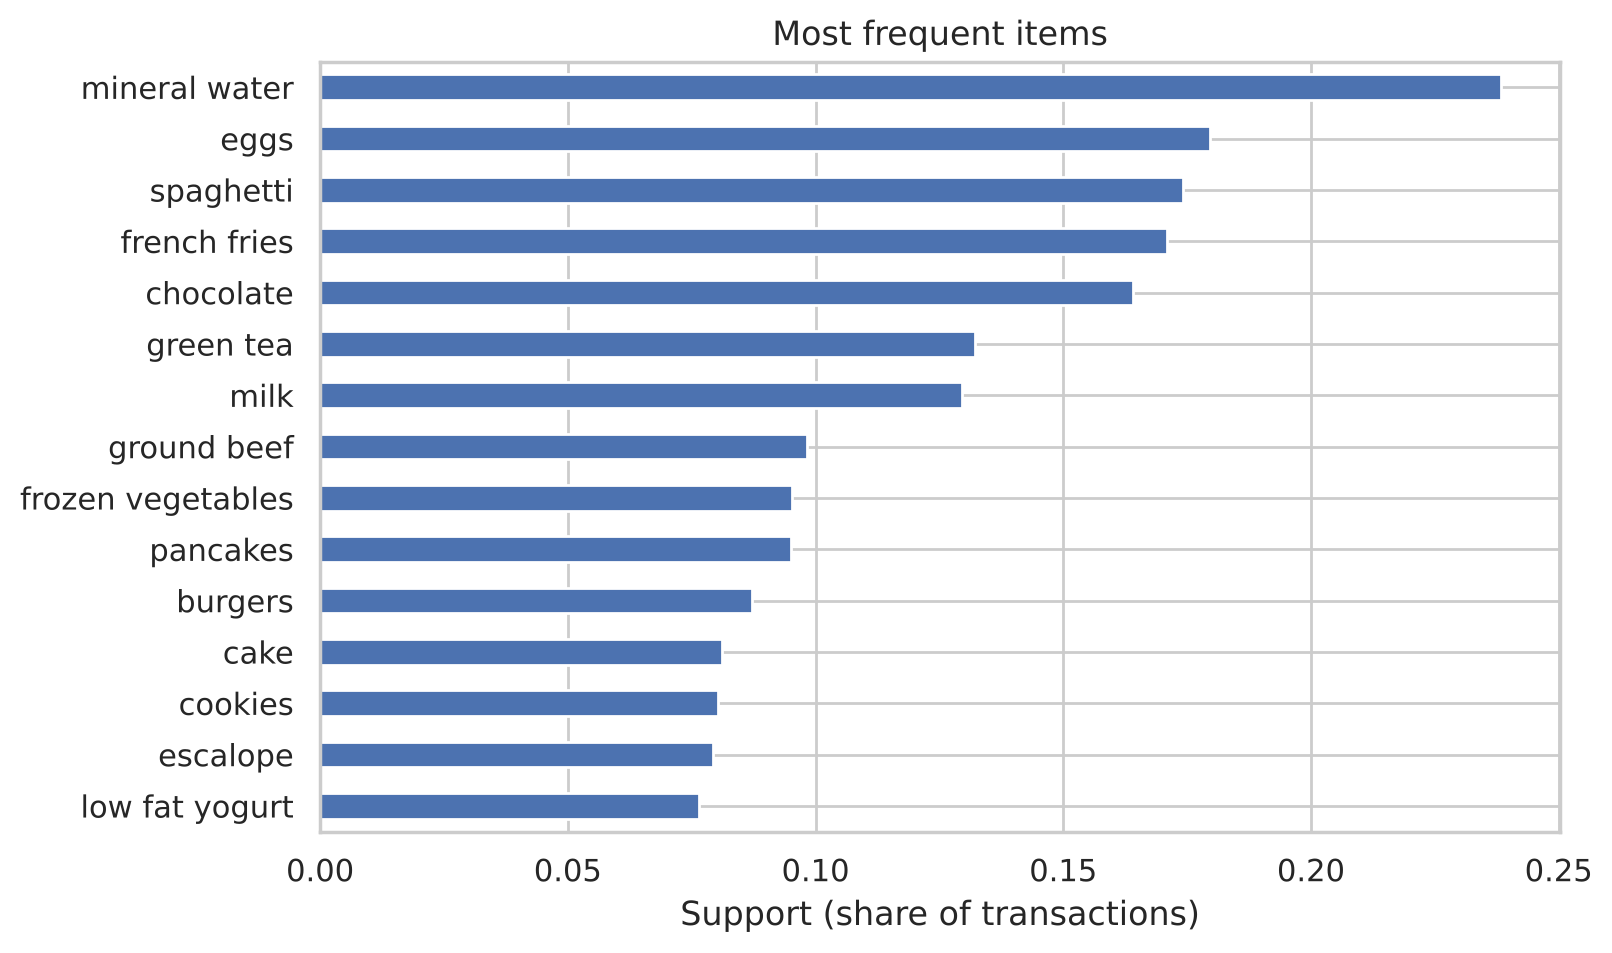

In [2]:
item_counts = pd.Series([item for t in transactions for item in t]).value_counts()
print("Number of distinct items:", len(item_counts))
(item_counts.head(15) / len(transactions)).plot.barh(figsize=(8, 5))
plt.gca().invert_yaxis()
plt.xlabel("Support (share of transactions)")
plt.title("Most frequent items")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تبدیل به قالب یک-داغ (one-hot)

الگوریتم‌ها به جدولی نیاز دارند که هر سطر یک تراکنش و هر ستون یک کالا باشد، با مقدار True اگر آن کالا در تراکنش هست:

</div>

In [3]:
from mlxtend.preprocessing import TransactionEncoder

encoder = TransactionEncoder()
basket = pd.DataFrame(encoder.fit_transform(transactions), columns=encoder.columns_)
basket.iloc[:5, :8]

,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea
0,True,True,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. الگوریتم Apriori

تعداد مجموعه‌های ممکن از ۱۲۰ کالا، $2^{120}$ است؛ امتحان همه غیرممکن است. **اصل Apriori** فضای جستجو را به‌شدت کوچک می‌کند:

> اگر یک مجموعهٔ کالا پرتکرار نباشد، هیچ ابرمجموعه‌ای از آن هم پرتکرار نیست.

اگر {خاویار} در کمتر از ۱٪ خریدها باشد، {خاویار، نان} هم حتماً کمتر از ۱٪ است و نیازی به بررسی آن نیست. Apriori ابتدا کالاهای تکی پرتکرار را پیدا می‌کند، سپس فقط از ترکیب آن‌ها جفت‌ها را می‌سازد و همین‌طور ادامه می‌دهد.

</div>

In [4]:
from mlxtend.frequent_patterns import apriori, association_rules

frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)
frequent_itemsets["size"] = frequent_itemsets["itemsets"].apply(len)
print("Frequent itemsets found:", len(frequent_itemsets))
print(frequent_itemsets["size"].value_counts().sort_index().rename("count by size"))
frequent_itemsets.sort_values("support", ascending=False).head(10)

Frequent itemsets found: 257
size
1     75
2    165
3     17
Name: count by size, dtype: int64


,support,itemsets,size
46,0.238368,frozenset({mineral water}),1
19,0.179709,frozenset({eggs}),1
63,0.174110,frozenset({spaghetti}),1
24,0.170911,frozenset({french fries}),1
13,0.163845,frozenset({chocolate}),1
32,0.132116,frozenset({green tea}),1
45,0.129583,frozenset({milk}),1
33,0.098254,frozenset({ground beef}),1
30,0.095321,frozenset({frozen vegetables}),1
53,0.095054,frozenset({pancakes}),1


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. استخراج قوانین

از مجموعه‌های پرتکرار، قوانینی را استخراج می‌کنیم که Lift بیشتر از ۱ دارند:

</div>

In [5]:
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]]
rules["antecedents"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
rules["consequents"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
print("Number of rules:", len(rules))
rules.sort_values("lift", ascending=False).head(12).round(3)

Number of rules: 406


,antecedents,consequents,support,confidence,lift
214,herb & pepper,ground beef,0.016,0.323,3.292
215,ground beef,herb & pepper,0.016,0.163,3.292
385,ground beef,"mineral water, spaghetti",0.017,0.174,2.908
384,"mineral water, spaghetti",ground beef,0.017,0.286,2.908
395,"mineral water, spaghetti",olive oil,0.010,0.172,2.610
398,olive oil,"mineral water, spaghetti",0.010,0.156,2.610
193,frozen vegetables,tomatoes,0.016,0.169,2.474
192,tomatoes,frozen vegetables,0.016,0.236,2.474
188,shrimp,frozen vegetables,0.017,0.233,2.447
189,frozen vegetables,shrimp,0.017,0.175,2.447


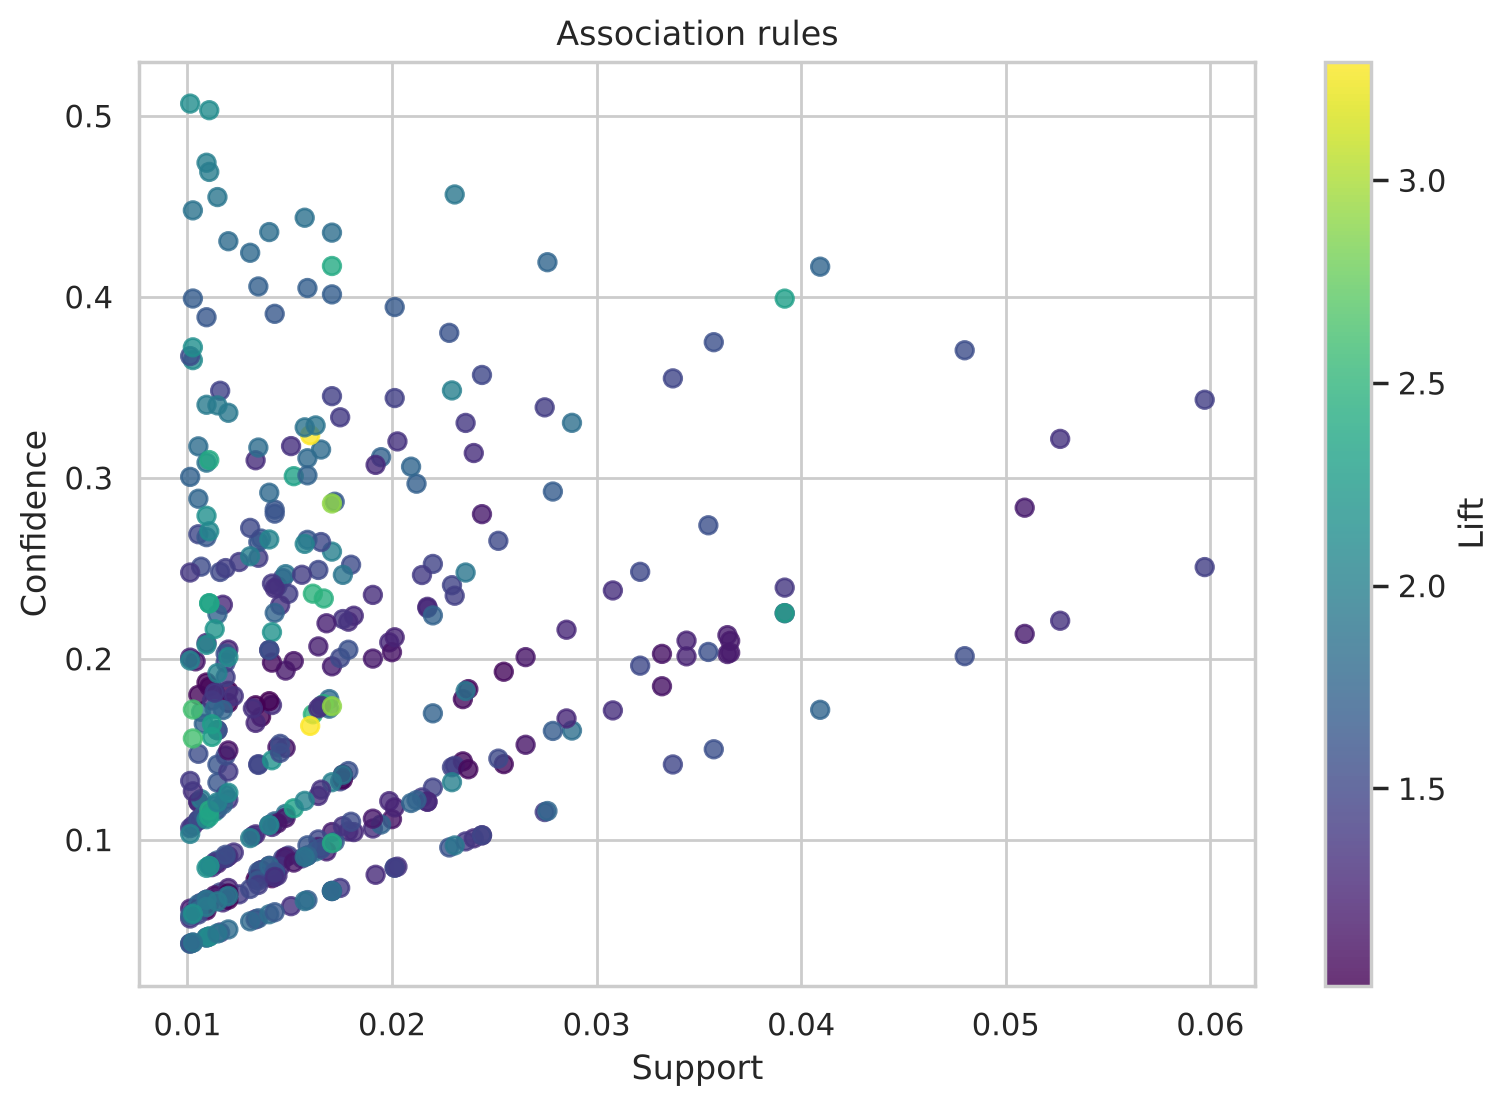

In [6]:
plt.figure(figsize=(9, 6))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=40, alpha=0.8)
plt.colorbar(sc, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association rules")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تفسیر:** قوانینی با Lift بالا رابطه‌های قوی‌تری نشان می‌دهند؛ مثلاً قوی‌ترین قانون بین ادویه (herb & pepper) و گوشت چرخ‌کرده است و بعد از آن، ترکیب گوشت چرخ‌کرده با اسپاگتی؛ کالاهایی که برای یک وعدهٔ غذایی با هم خریده می‌شوند. توجه کنید که قانون‌ها معمولاً در هر دو جهت با Lift یکسان ظاهر می‌شوند، چون Lift متقارن است؛ ولی Confidence دو جهت متفاوت است.

### استفادهٔ عملی: پیشنهاد محصول

</div>

In [7]:
def recommend(item, rules, top_n=5):
    matches = rules[rules["antecedents"] == item].sort_values("lift", ascending=False)
    return matches[["consequents", "confidence", "lift"]].head(top_n).round(3)

recommend("ground beef", rules)

,consequents,confidence,lift
215,herb & pepper,0.163,3.292
385,"mineral water, spaghetti",0.174,2.908
379,"milk, mineral water",0.113,2.347
226,spaghetti,0.399,2.291
194,grated cheese,0.115,2.201


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**هشدار:** قوانین انجمنی **همبستگی** را نشان می‌دهند، نه علیت. همچنین نتیجه به آستانهٔ `min_support` بسیار حساس است: آستانهٔ خیلی کم، هزاران قانون تصادفی و آستانهٔ خیلی زیاد، فقط قوانین بدیهی دربارهٔ کالاهای پرفروش تولید می‌کند.

### FP-Growth

Apriori باید چندین بار کل داده را مرور کند. **FP-Growth** داده را در یک ساختار درختی فشرده ذخیره می‌کند و همان نتیجه را سریع‌تر می‌دهد؛ این تفاوت در داده‌های بزرگ چشمگیر می‌شود:

</div>

In [8]:
import time
from mlxtend.frequent_patterns import fpgrowth

for name, algorithm in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
    start = time.perf_counter()
    result = algorithm(basket, min_support=0.005, use_colnames=True)
    print(f"{name:<10} {len(result)} itemsets in {time.perf_counter() - start:.2f} s")

Apriori    725 itemsets in 0.08 s
FP-Growth  725 itemsets in 0.06 s


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## بخش دوم: تشخیص ناهنجاری (Anomaly Detection)

## ۶. ناهنجاری چیست؟

**ناهنجاری (Anomaly)** یا **دادهٔ پرت (Outlier)** نمونه‌ای است که به‌طور قابل توجهی با بقیهٔ داده‌ها متفاوت است. کاربردها:

- **تشخیص تقلب** در تراکنش‌های بانکی
- **امنیت شبکه**: تشخیص نفوذ و حمله
- **پایش صنعتی**: تشخیص خرابی دستگاه از روی دادهٔ حسگرها
- **پاک‌سازی داده** قبل از مدل‌سازی

دو حالت متفاوت:
- **تشخیص پرت (Outlier Detection):** دادهٔ آموزش خودش آلوده به ناهنجاری است و می‌خواهیم آن‌ها را پیدا کنیم.
- **تشخیص نوآوری (Novelty Detection):** دادهٔ آموزش «پاک» است و می‌خواهیم نمونه‌های **جدید** غیرعادی را تشخیص دهیم.

معمولاً برچسب کافی برای ناهنجاری‌ها نداریم (یا ناهنجاری‌ها بسیار نادر و متنوع‌اند)، پس این مسئله اغلب **بدون نظارت** حل می‌شود.

## ۷. روش‌های آماری ساده (تک‌متغیره)

- **Z-score:** نمونه‌هایی که بیش از ۳ انحراف معیار از میانگین فاصله دارند. ولی خود میانگین و انحراف معیار به دادهٔ پرت حساس‌اند.
- **IQR (دامنهٔ میان‌چارکی):** نمونه‌های بیرون از بازهٔ $[Q_1 - 1.5\,\text{IQR},\ Q_3 + 1.5\,\text{IQR}]$؛ همان قاعده‌ای که در نمودار جعبه‌ای (box plot) استفاده می‌شود. مقاوم‌تر است.

</div>

Z-score outliers (|z| > 3): [12. 85. 90. 95.]
IQR outliers:               [12.  34.5 35.3 65.3 85.  90.  95. ]


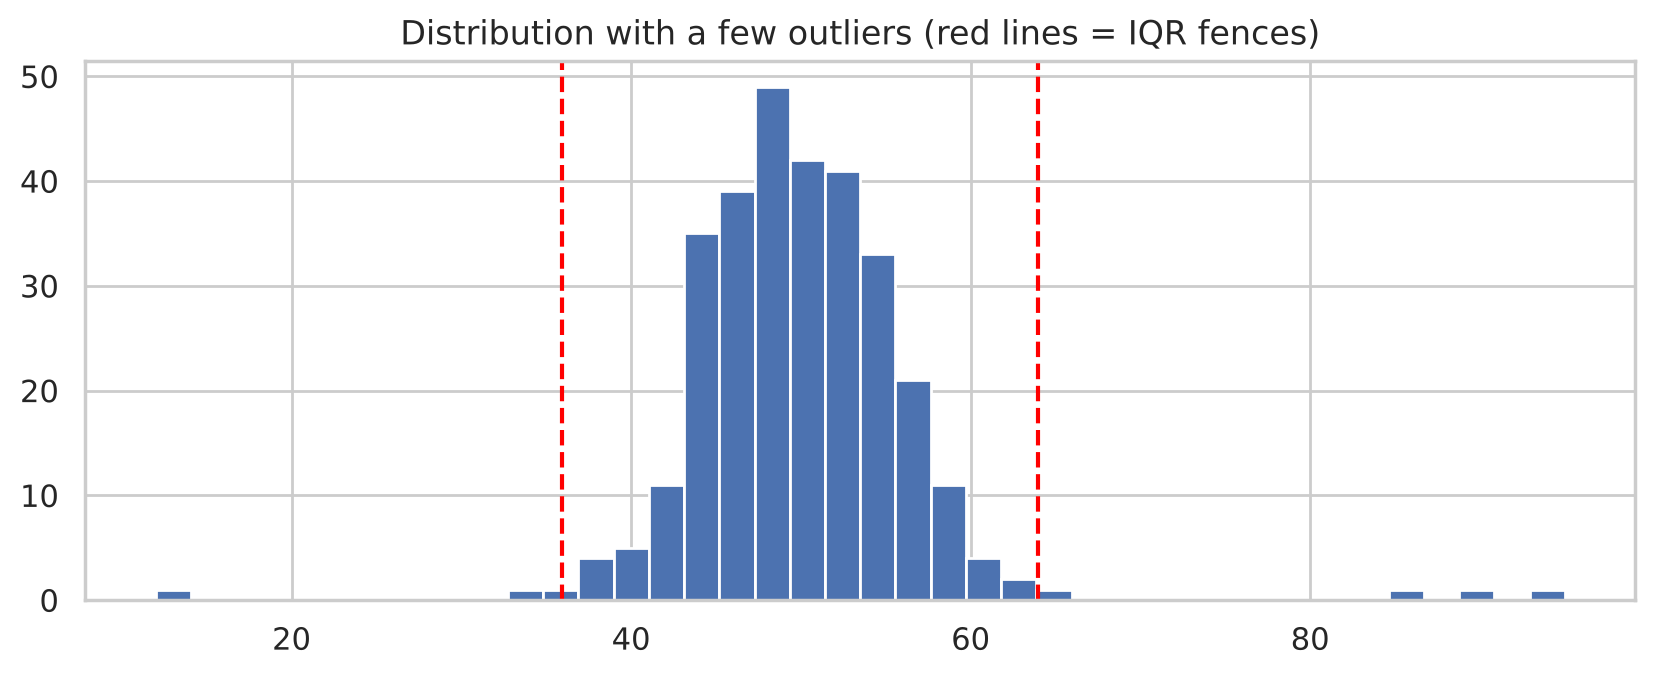

In [9]:
rng = np.random.default_rng(0)
values = np.concatenate([rng.normal(50, 5, 300), [85, 90, 12, 95]])

z = (values - values.mean()) / values.std()
q1, q3 = np.percentile(values, [25, 75])
iqr = q3 - q1
iqr_outliers = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

print("Z-score outliers (|z| > 3):", np.sort(values[np.abs(z) > 3]).round(1))
print("IQR outliers:              ", np.sort(values[iqr_outliers]).round(1))

plt.figure(figsize=(10, 3.5))
plt.hist(values, bins=40)
for fence in [q1 - 1.5 * iqr, q3 + 1.5 * iqr]:
    plt.axvline(fence, color="red", linestyle="--")
plt.title("Distribution with a few outliers (red lines = IQR fences)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر دو روش ۴ دادهٔ پرت واقعی را پیدا کرده‌اند. IQR چند نقطهٔ عادی از دنباله‌های توزیع نرمال را هم پرت تشخیص داده؛ یعنی قاعدهٔ ۱٫۵ برابر IQR برای دادهٔ نرمال کمی سخت‌گیرانه است و نقاطی که پیدا می‌کند فقط «مشکوک»اند، نه لزوماً خطا.

روش‌های تک‌متغیره ناهنجاری‌هایی را که فقط در **ترکیب** ویژگی‌ها غیرعادی‌اند نمی‌بینند؛ مثلاً قد ۱۹۰ سانتی‌متر و وزن ۴۵ کیلوگرم هر کدام به‌تنهایی عادی‌اند ولی با هم غیرعادی. برای این موارد به روش‌های چندمتغیره نیاز داریم.

## ۸. روش‌های یادگیری ماشین

| روش | ایده |
|---|---|
| **Isolation Forest** | ناهنجاری‌ها کم و متفاوت‌اند، پس با تقسیم‌های تصادفی **زودتر جدا (ایزوله)** می‌شوند. طول کوتاه مسیر در درخت‌های تصادفی یعنی ناهنجاری. سریع و مناسب دادهٔ بزرگ و پرابعاد. |
| **Local Outlier Factor (LOF)** | چگالی اطراف هر نقطه را با چگالی همسایه‌هایش مقایسه می‌کند. نقطه‌ای که از همسایه‌هایش بسیار کم‌چگال‌تر است، ناهنجار است. خوب برای خوشه‌هایی با چگالی متفاوت. |
| **One-Class SVM** | مرزی دور ناحیهٔ داده‌های عادی یاد می‌گیرد؛ هرچه بیرون مرز باشد ناهنجار است. حساس به ابرپارامترها و کند برای دادهٔ بزرگ. |
| **Elliptic Envelope** | فرض می‌کند دادهٔ عادی توزیع نرمال دارد و یک بیضی مقاوم (با برآورد کوواریانس با کمترین دترمینان، MCD) دور آن برازش می‌دهد. |

ابرپارامتر مشترک مهم: **`contamination`**، یعنی نسبت تخمینی ناهنجاری‌ها در داده که آستانهٔ تصمیم را تعیین می‌کند.

داده‌ای مصنوعی می‌سازیم که ناهنجاری‌هایش را می‌شناسیم تا بتوانیم روش‌ها را ارزیابی کنیم:

</div>

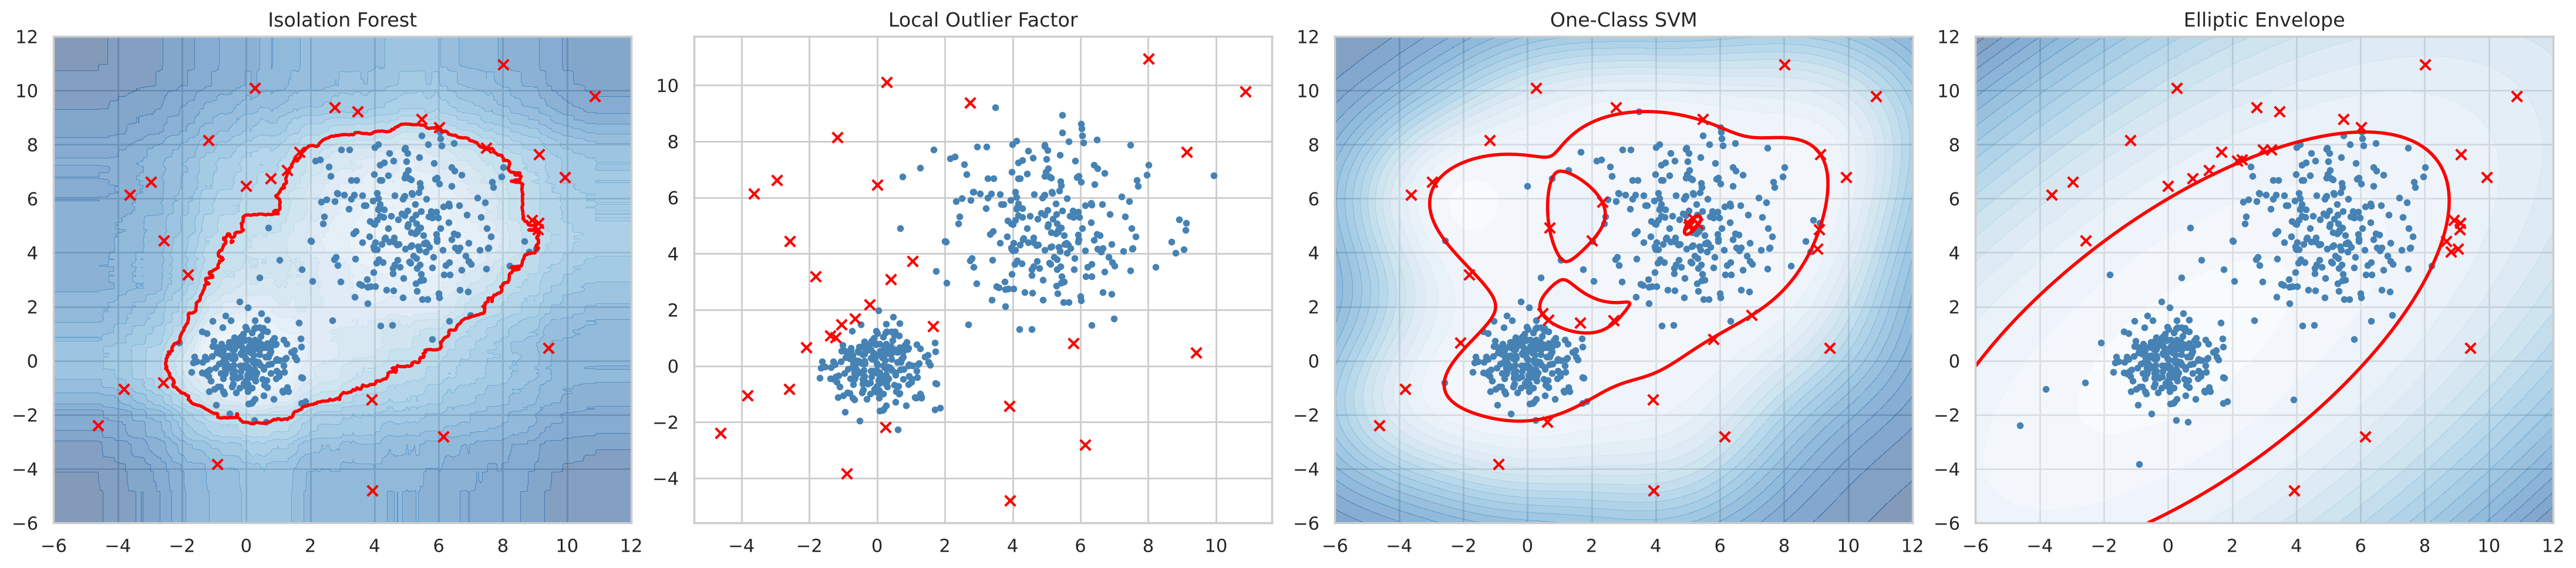

,precision,recall
method,,
Isolation Forest,0.633,0.633
Local Outlier Factor,0.667,0.667
One-Class SVM,0.514,0.600
Elliptic Envelope,0.500,0.500


In [10]:
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import precision_score, recall_score

X_normal, _ = make_blobs(n_samples=470, centers=[[0, 0], [5, 5]], cluster_std=[0.8, 1.6], random_state=42)
X_anomaly = rng.uniform(-5, 11, size=(30, 2))
X_all = np.vstack([X_normal, X_anomaly])
is_anomaly = np.r_[np.zeros(len(X_normal)), np.ones(len(X_anomaly))].astype(int)
contamination = 0.06

detectors = {
    "Isolation Forest": IsolationForest(contamination=contamination, random_state=42),
    "Local Outlier Factor": LocalOutlierFactor(n_neighbors=20, contamination=contamination),
    "One-Class SVM": OneClassSVM(nu=contamination, gamma=0.1),
    "Elliptic Envelope": EllipticEnvelope(contamination=contamination, random_state=42),
}

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
rows = []
for ax, (name, det) in zip(axes, detectors.items()):
    pred = det.fit_predict(X_all)          # +1 = normal, -1 = anomaly
    flagged = (pred == -1).astype(int)
    rows.append({"method": name, "precision": precision_score(is_anomaly, flagged),
                 "recall": recall_score(is_anomaly, flagged)})
    if name != "Local Outlier Factor":
        xx, yy = np.meshgrid(np.linspace(-6, 12, 300), np.linspace(-6, 12, 300))
        Z = det.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.contourf(xx, yy, Z, levels=20, cmap="Blues_r", alpha=0.5)
        ax.contour(xx, yy, Z, levels=[0], colors="red", linewidths=2)
    ax.scatter(X_all[flagged == 0, 0], X_all[flagged == 0, 1], s=10, c="steelblue")
    ax.scatter(X_all[flagged == 1, 0], X_all[flagged == 1, 1], s=40, c="red", marker="x")
    ax.set_title(name)
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("method").round(3)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- خط قرمز، مرز تصمیم هر روش است و ضربدرهای قرمز نقاطی‌اند که ناهنجار تشخیص داده شده‌اند.
- **Elliptic Envelope** یک بیضی واحد دور کل داده برازش می‌دهد و چون داده دو خوشه دارد، فرضش برقرار نیست.
- **Isolation Forest** و **LOF** بدون هیچ فرضی دربارهٔ شکل داده، معمولاً عملکرد خوبی دارند.
- بعضی نقاط تصادفی که «ناهنجار» ساخته‌ایم، اتفاقاً داخل خوشه‌های عادی افتاده‌اند و هیچ روشی نمی‌تواند آن‌ها را تشخیص دهد؛ به همین دلیل Recall هیچ روشی ۱۰۰٪ نیست.

## ۹. استفادهٔ درست: آموزش روی دادهٔ آموزش، اعمال روی دادهٔ جدید

یک اشتباه رایج (که در نسخهٔ قبلی این دوره هم وجود داشت): حذف داده‌های پرت با `fit_predict` روی **کل داده**، قبل از تقسیم آموزش و آزمون. این کار دو مشکل دارد:
1. اطلاعات دادهٔ آزمون در تصمیم‌گیری دربارهٔ پرت‌ها استفاده شده است (**نشت داده**).
2. دادهٔ آزمون «تمیز» شده و دیگر نمایندهٔ دادهٔ واقعی نیست؛ در دنیای واقعی، داده‌های جدید هم پرت دارند.

روش درست: آشکارساز را **فقط روی دادهٔ آموزش** `fit` کنید و برای دادهٔ جدید از `predict` یا `decision_function` استفاده کنید. برای LOF باید `novelty=True` باشد تا `predict` روی دادهٔ جدید فعال شود.

</div>

In [11]:
from sklearn.model_selection import train_test_split

X_tr, X_te, a_tr, a_te = train_test_split(X_all, is_anomaly, test_size=0.3, stratify=is_anomaly, random_state=42)

iso = IsolationForest(contamination=contamination, random_state=42).fit(X_tr)
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination, novelty=True).fit(X_tr)

for name, det in [("Isolation Forest", iso), ("LOF (novelty=True)", lof)]:
    flagged = (det.predict(X_te) == -1).astype(int)
    print(f"{name:<20} test precision={precision_score(a_te, flagged):.2f}  recall={recall_score(a_te, flagged):.2f}")

Isolation Forest     test precision=0.67  recall=0.67
LOF (novelty=True)   test precision=0.46  recall=0.67


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### امتیاز ناهنجاری به‌جای برچسب قطعی

در عمل، به‌جای برچسب قطعی، معمولاً **امتیاز ناهنجاری** را محاسبه و نمونه‌ها را بر اساس آن رتبه‌بندی می‌کنیم تا کارشناس، موارد مشکوک‌تر را اول بررسی کند. در scikit-learn، `score_samples` امتیازی می‌دهد که هرچه **کمتر** باشد، نمونه **غیرعادی‌تر** است:

</div>

In [12]:
scores = -iso.score_samples(X_te)       # higher = more anomalous
top = np.argsort(scores)[::-1][:10]
print("Share of true anomalies among the 10 most suspicious test points:", a_te[top].mean())

Share of true anomalies among the 10 most suspicious test points: 0.6


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## جمع‌بندی

**قوانین انجمنی**
- Support محبوبیت، Confidence احتمال شرطی و Lift قدرت رابطه را نسبت به حالت مستقل می‌سنجد.
- اصل Apriori جستجو را ممکن می‌کند؛ FP-Growth همان نتیجه را سریع‌تر می‌دهد.
- قوانین را بر اساس Lift و با Support کافی انتخاب کنید و به یاد داشته باشید که همبستگی، علیت نیست.

**تشخیص ناهنجاری**
- روش‌های تک‌متغیره (Z-score و IQR) ساده‌اند ولی ناهنجاری‌های ترکیبی را نمی‌بینند.
- Isolation Forest انتخاب پیش‌فرض خوبی است؛ LOF برای چگالی‌های متفاوت و Elliptic Envelope برای دادهٔ تقریباً نرمال.
- آشکارساز را فقط روی دادهٔ آموزش `fit` کنید و `contamination` را با دانش حوزه تنظیم کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. قوانین انجمنی را با `min_support=0.005` استخراج کنید. چند قانون با Lift بیشتر از ۳ پیدا می‌شود؟ آیا معنادارند؟

۲. قوانینی را پیدا کنید که «mineral water» تالی آن‌ها است. چرا بسیاری از قوانین این داده به آب معدنی ختم می‌شوند؟ (راهنمایی: Support آب معدنی را ببینید.)

۳. در Isolation Forest، `contamination` را ۰٫۰۲، ۰٫۰۶ و ۰٫۱۵ قرار دهید و Precision و Recall را مقایسه کنید.

۴. روی دادهٔ ریزش مشتری جلسهٔ ۱۰، Isolation Forest را روی ویژگی‌های عددی اجرا کنید و ۲۰ مشتری غیرعادی‌تر را بررسی کنید. چه چیزی آن‌ها را غیرعادی کرده است؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** قوانین انجمنی را با `min_support=0.005` استخراج کنید. چند قانون با Lift بیشتر از ۳ پیدا می‌شود؟ آیا معنادارند؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** قوانینی را پیدا کنید که «mineral water» تالی آن‌ها است. چرا بسیاری از قوانین این داده به آب معدنی ختم می‌شوند؟ (راهنمایی: Support آب معدنی را ببینید.)

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** در Isolation Forest، `contamination` را ۰٫۰۲، ۰٫۰۶ و ۰٫۱۵ قرار دهید و Precision و Recall را مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** روی دادهٔ ریزش مشتری جلسهٔ ۱۰، Isolation Forest را روی ویژگی‌های عددی اجرا کنید و ۲۰ مشتری غیرعادی‌تر را بررسی کنید. چه چیزی آن‌ها را غیرعادی کرده است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
